Plant Leaf Disease Detection Using Image Processing and Transfer Learning

## 1. Import Libraries

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Paths

In [5]:
PROJECT_ROOT = os.path.abspath("..")

TRAIN_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "train"
)

VALIDATION_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "validation"
)

TEST_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "test"
)

print("Training directory:")
print(TRAIN_DIR)

print("\nValidation directory:")
print(VALIDATION_DIR)

print("\nTesting directory:")
print(TEST_DIR)

Training directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\train

Validation directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\validation

Testing directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\test


## 3. Dataset Information

In [6]:
classes = [
    "healthy",
    "early_blight",
    "late_blight",
    "leaf_mold"
]

for class_name in classes:

    folder = os.path.join(
        TRAIN_DIR,
        class_name
    )

    count = len([
        file for file in os.listdir(folder)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    print(f"{class_name:15s}: {count}")

healthy        : 400
early_blight   : 400
late_blight    : 400
leaf_mold      : 400


## 4. Sample Images

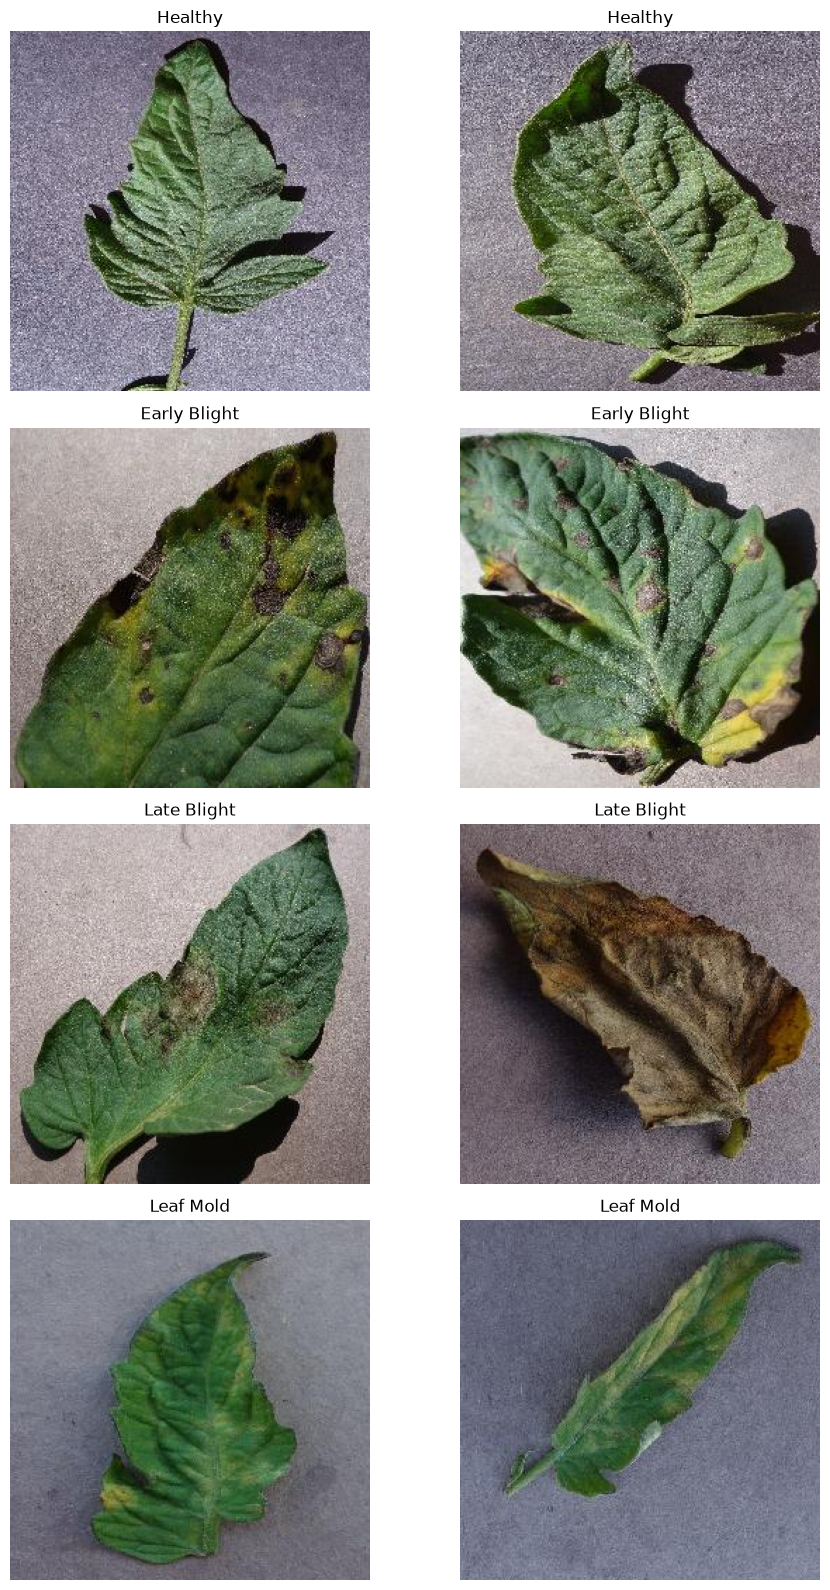

In [7]:
fig, axes = plt.subplots(
    4,
    2,
    figsize=(10, 16)
)

for row, class_name in enumerate(classes):

    folder = os.path.join(
        TRAIN_DIR,
        class_name
    )

    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    selected_images = images[:2]

    for col, image_file in enumerate(selected_images):

        image_path = os.path.join(
            folder,
            image_file
        )

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            class_name.replace("_", " ").title()
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


## 5. Dataset Analysis

In this section, we analyze the distribution of images across
the four tomato leaf categories in the training, validation,
and testing datasets.

In [8]:
import os
import pandas as pd

classes = [
    "healthy",
    "early_blight",
    "late_blight",
    "leaf_mold"
]

splits = ["train", "validation", "test"]

dataset_counts = {}

for split in splits:

    split_dir = os.path.join(PROJECT_ROOT, "data", "processed", split)

    dataset_counts[split] = {}

    for class_name in classes:

        class_dir = os.path.join(split_dir, class_name)

        image_files = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        dataset_counts[split][class_name] = len(image_files)


df_counts = pd.DataFrame(dataset_counts)

df_counts

,train,validation,test
healthy,400,50,50
early_blight,400,50,50
late_blight,400,50,50
leaf_mold,400,50,50


In [9]:
print("DATASET SUMMARY")
print("-" * 40)

for split in splits:

    total = sum(dataset_counts[split].values())

    print(f"{split.capitalize()} images: {total}")

total_images = sum(
    sum(dataset_counts[split].values())
    for split in splits
)

print("-" * 40)
print("Total images:", total_images)

DATASET SUMMARY
----------------------------------------
Train images: 1600
Validation images: 200
Test images: 200
----------------------------------------
Total images: 2000


## 5.1 Class Distribution Visualization

A bar chart is used to visualize the number of images
available in each category across the three dataset splits.

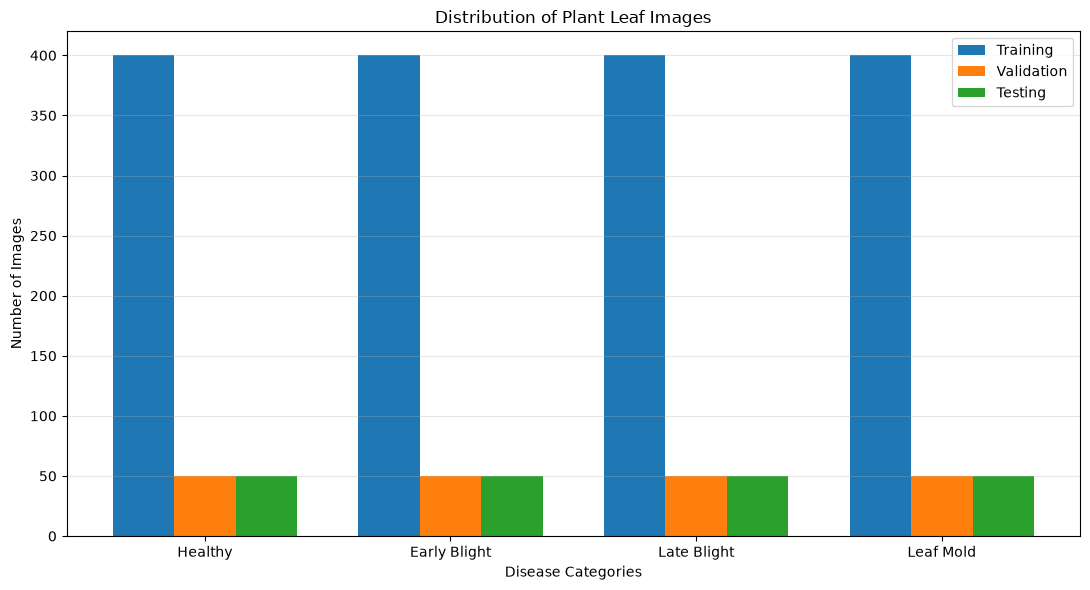

In [10]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    df_counts["train"],
    width,
    label="Training"
)

plt.bar(
    x,
    df_counts["validation"],
    width,
    label="Validation"
)

plt.bar(
    x + width,
    df_counts["test"],
    width,
    label="Testing"
)

plt.xlabel("Disease Categories")
plt.ylabel("Number of Images")

plt.title("Distribution of Plant Leaf Images")

plt.xticks(
    x,
    ["Healthy", "Early Blight", "Late Blight", "Leaf Mold"]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

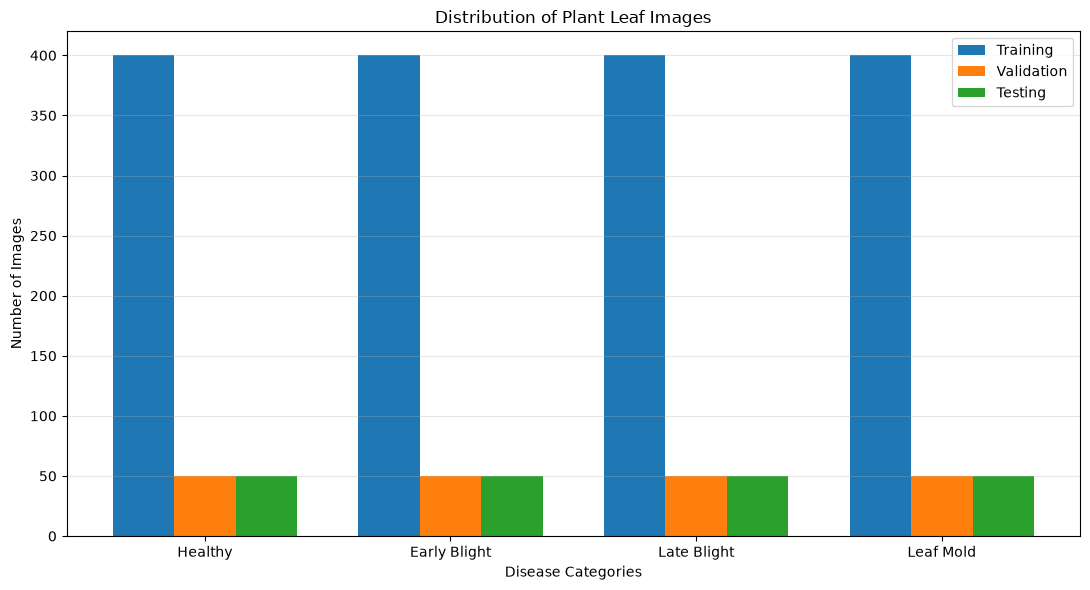

In [11]:
os.makedirs(
    os.path.join(PROJECT_ROOT, "results"),
    exist_ok=True
)

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    df_counts["train"],
    width,
    label="Training"
)

plt.bar(
    x,
    df_counts["validation"],
    width,
    label="Validation"
)

plt.bar(
    x + width,
    df_counts["test"],
    width,
    label="Testing"
)

plt.xlabel("Disease Categories")
plt.ylabel("Number of Images")
plt.title("Distribution of Plant Leaf Images")

plt.xticks(
    x,
    ["Healthy", "Early Blight", "Late Blight", "Leaf Mold"]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_ROOT, "results", "class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPU available: []


In [13]:
IMAGE_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

NUM_CLASSES = 4

In [14]:
train_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED

)

Found 1600 files belonging to 4 classes.


In [15]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(

    VALIDATION_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

Found 200 files belonging to 4 classes.


In [16]:
test_dataset = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

Found 200 files belonging to 4 classes.


In [17]:
class_names = train_dataset.class_names

print("Classes detected by TensorFlow:")

for i, name in enumerate(class_names):

    print(i, ":", name)

Classes detected by TensorFlow:
0 : early_blight
1 : healthy
2 : late_blight
3 : leaf_mold


In [18]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)

    print("Label batch shape:", labels.shape)

    print("Image data type:", images.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())

    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 251.58191


## 6. Resized Images

All input images are resized to 224 × 224 pixels
while retaining their RGB color channels.

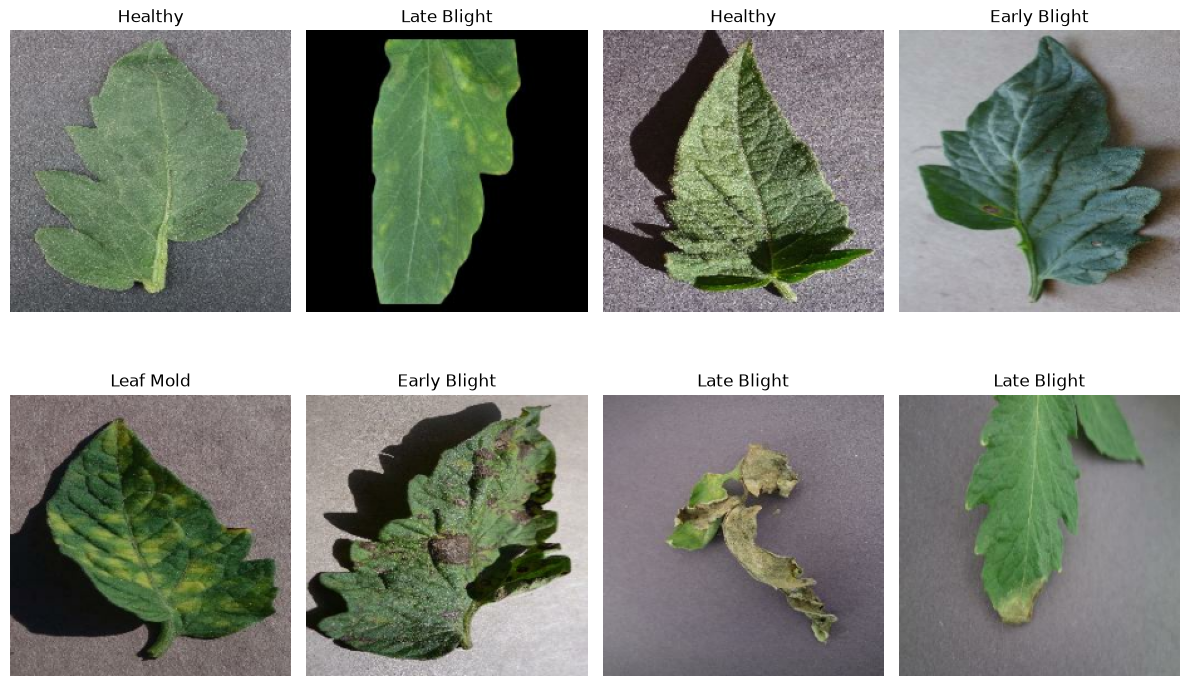

In [19]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(8):

        ax = plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = class_names[labels[i].numpy()]

        plt.title(label.replace("_", " ").title())

        plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Data Augmentation

Data augmentation is used to artificially introduce variations
in the training images. This helps improve the generalization
ability of the model and reduces overfitting.

In [20]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.10),

    tf.keras.layers.RandomZoom(0.10)

], name="data_augmentation")

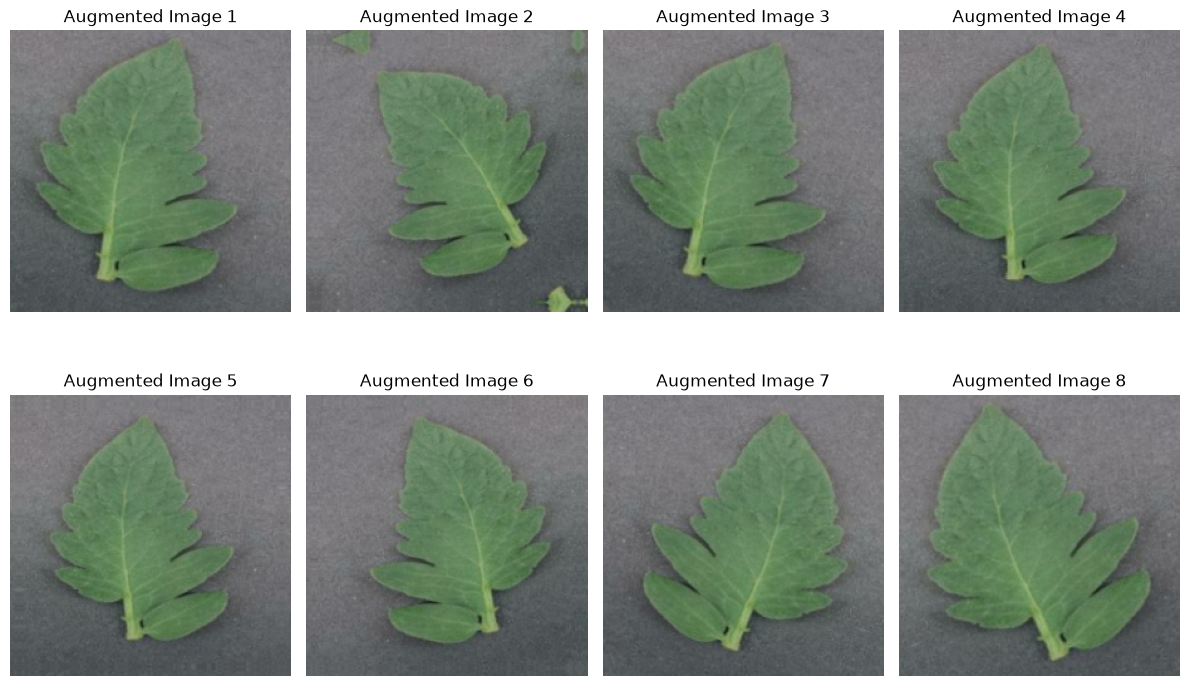

In [21]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    original_image = images[0]

    for i in range(8):

        augmented_image = data_augmentation(
            tf.expand_dims(original_image, 0),
            training=True
        )

        augmented_image = augmented_image[0]

        ax = plt.subplot(2, 4, i + 1)

        plt.imshow(
            tf.clip_by_value(
                augmented_image / 255.0,
                0,
                1
            )
        )

        plt.title(f"Augmented Image {i+1}")

        plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Dataset Performance Optimization

Prefetching is used to improve the efficiency of the
input pipeline by preparing subsequent batches while
the current batch is being processed.

In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset optimization completed.")

Dataset optimization completed.


In [23]:
print("FINAL DATASET VERIFICATION")
print("=" * 45)

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

print("\nClass names:")

for i, name in enumerate(class_names):
    print(i, ":", name)

print("\nDataset batches:")

print(
    "Training batches:",
    tf.data.experimental.cardinality(train_dataset).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(validation_dataset).numpy()
)

print(
    "Testing batches:",
    tf.data.experimental.cardinality(test_dataset).numpy()
)

FINAL DATASET VERIFICATION
Image size: (224, 224)
Batch size: 32
Number of classes: 4

Class names:
0 : early_blight
1 : healthy
2 : late_blight
3 : leaf_mold

Dataset batches:
Training batches: 50
Validation batches: 7
Testing batches: 7


In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [25]:
print("Class names:", class_names)
print("Number of classes:", len(class_names))

print("\nTraining batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Class names: ['early_blight', 'healthy', 'late_blight', 'leaf_mold']
Number of classes: 4

Training batches: 50
Validation batches: 7
Testing batches: 7


In [26]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully.")
print("Number of layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully.
Number of layers: 154


In [27]:
base_model.trainable = False

print("Base model trainable:", base_model.trainable)

Base model trainable: False


In [28]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing: [0,255] -> [-1,1]
x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

# Pretrained MobileNetV2
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.2)(x)

# Our 4-class classifier
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [29]:
print("Total parameters:", model.count_params())
print(
    "Trainable parameters:",
    sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
)
print(
    "Non-trainable parameters:",
    sum(tf.keras.backend.count_params(w) for w in model.non_trainable_weights)
)

Total parameters: 2263108
Trainable parameters: 5124
Non-trainable parameters: 2257984


In [30]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [31]:
import os

os.makedirs(
    os.path.join(PROJECT_ROOT, "models"),
    exist_ok=True
)

checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "mobilenetv2_best.keras"
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Callbacks configured.")
print("Best model will be saved to:")
print(checkpoint_path)

Callbacks configured.
Best model will be saved to:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_best.keras


In [32]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10


c:\PROJECTS\Plant-Disease-Detection-IPA-Model\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.6812 - loss: 0.8124
Epoch 1: val_accuracy improved from None to 0.77500, saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_best.keras

Epoch 1: finished saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 44s 730ms/step - accuracy: 0.6812 - loss: 0.8124 - val_accuracy: 0.7750 - val_loss: 0.5765 - learning_rate: 0.0010
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.8462 - loss: 0.4416
Epoch 2: val_accuracy improved from 0.77500 to 0.84000, saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_best.keras

Epoch 2: finished saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 629ms/step - accuracy: 0.8462 - loss: 0.4416 - val_accuracy: 0.8400 - val_loss: 0.4539 - learning_rate: 0.0010
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s

In [33]:
print("Best validation accuracy:")

best_val_accuracy = max(
    history.history["val_accuracy"]
)

print(f"{best_val_accuracy * 100:.2f}%")

Best validation accuracy:
91.00%


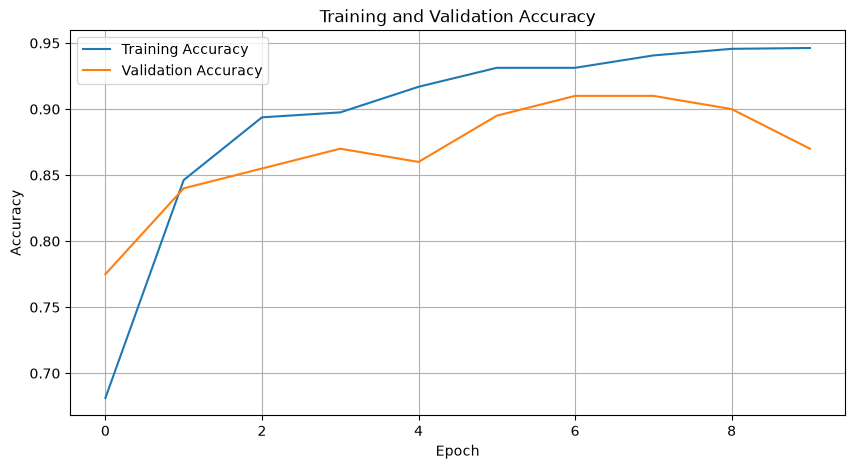

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

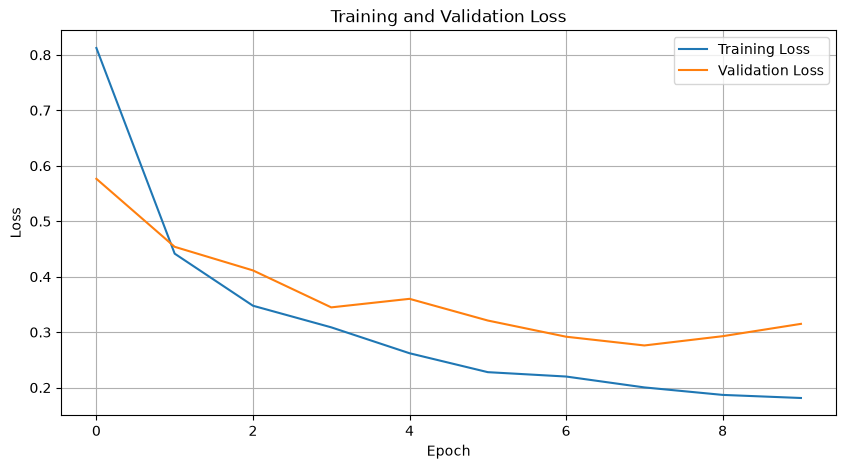

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

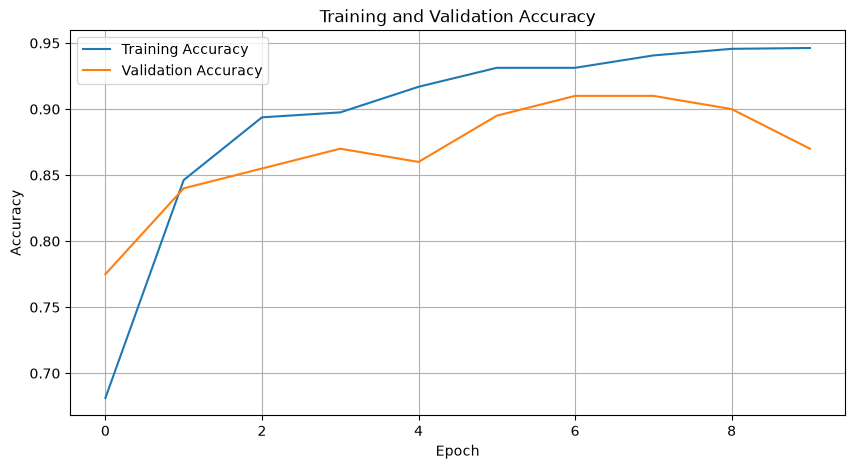

In [36]:
results_dir = os.path.join(
    PROJECT_ROOT,
    "results"
)

os.makedirs(results_dir, exist_ok=True)

# Accuracy plot
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        results_dir,
        "training_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

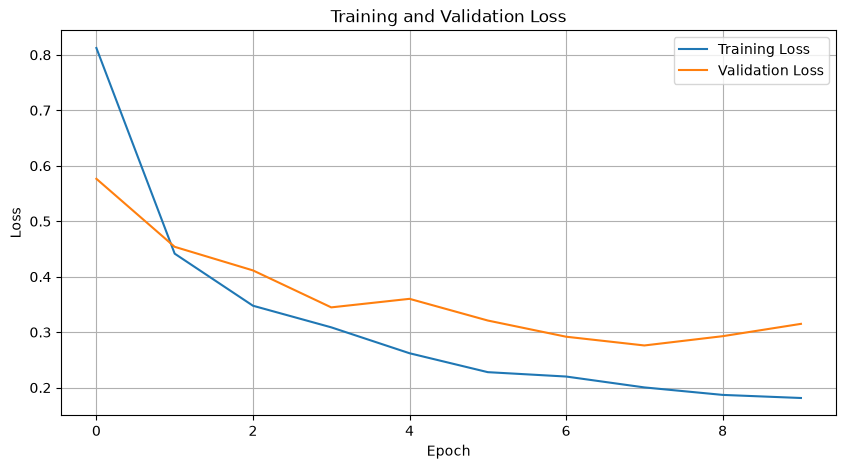

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        results_dir,
        "training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
best_model_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "mobilenetv2_best.keras"
)

model = tf.keras.models.load_model(best_model_path)

print("Best frozen model loaded successfully.")

Best frozen model loaded successfully.


In [39]:
print("Evaluating the best frozen model on validation data...")

val_loss, val_accuracy = model.evaluate(
    validation_dataset,
    verbose=1
)

print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Evaluating the best frozen model on validation data...
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 846ms/step - accuracy: 0.9100 - loss: 0.2918

Validation Loss: 0.2918
Validation Accuracy: 91.00%


In [40]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__, layer.trainable)

0 input_layer_2 InputLayer True
1 data_augmentation Sequential True
2 rescaling Rescaling True
3 mobilenetv2_1.00_224 Functional False
4 global_average_pooling2d GlobalAveragePooling2D True
5 dropout Dropout True
6 dense Dense True


In [41]:
base_model = model.get_layer(
    "mobilenetv2_1.00_224"
)

print("MobileNetV2 layers:", len(base_model.layers))

MobileNetV2 layers: 154


In [42]:
base_model.trainable = True

print("MobileNetV2 trainable:", base_model.trainable)

MobileNetV2 trainable: True


In [43]:
fine_tune_at = len(base_model.layers) - 30

print("Fine-tuning from layer:", fine_tune_at)
print("Total MobileNetV2 layers:", len(base_model.layers))

Fine-tuning from layer: 124
Total MobileNetV2 layers: 154


In [44]:
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

In [45]:
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Batch Normalization layers kept frozen.")

Batch Normalization layers kept frozen.


In [46]:
trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model.non_trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)
print(
    "Total parameters:",
    trainable_params + non_trainable_params
)

Trainable parameters: 1515844
Non-trainable parameters: 747264
Total parameters: 2263108


In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully.")
print("Learning rate: 1e-5")

Fine-tuning model compiled successfully.
Learning rate: 1e-5


In [48]:
fine_tuned_model_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "mobilenetv2_finetuned_best.keras"
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=fine_tuned_model_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning callbacks configured.")
print("Best fine-tuned model:")
print(fine_tuned_model_path)

Fine-tuning callbacks configured.
Best fine-tuned model:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras


In [49]:
FINE_TUNE_EPOCHS = 8

fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)

Epoch 1/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.9544 - loss: 0.1671
Epoch 1: val_accuracy improved from None to 0.91500, saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 40s 695ms/step - accuracy: 0.9544 - loss: 0.1671 - val_accuracy: 0.9150 - val_loss: 0.2391 - learning_rate: 1.0000e-05
Epoch 2/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.9519 - loss: 0.1397
Epoch 2: val_accuracy improved from 0.91500 to 0.93500, saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 575ms/step - accuracy: 0.9519 - loss: 0.1397 - val_accuracy: 0.9350 - val_loss: 0.2064 - learning_

In [50]:
best_fine_tune_accuracy = max(
    fine_tune_history.history["val_accuracy"]
)

print(
    f"Best fine-tuned validation accuracy: "
    f"{best_fine_tune_accuracy * 100:.2f}%"
)

Best fine-tuned validation accuracy: 94.00%


In [51]:
original_accuracy = best_val_accuracy
fine_tuned_accuracy = best_fine_tune_accuracy

print("Model comparison")
print("-" * 40)

print(
    f"Frozen MobileNetV2: "
    f"{original_accuracy * 100:.2f}%"
)

print(
    f"Fine-tuned MobileNetV2: "
    f"{fine_tuned_accuracy * 100:.2f}%"
)

improvement = (
    fine_tuned_accuracy - original_accuracy
) * 100

print(
    f"Improvement: "
    f"{improvement:+.2f} percentage points"
)

Model comparison
----------------------------------------
Frozen MobileNetV2: 91.00%
Fine-tuned MobileNetV2: 94.00%
Improvement: +3.00 percentage points


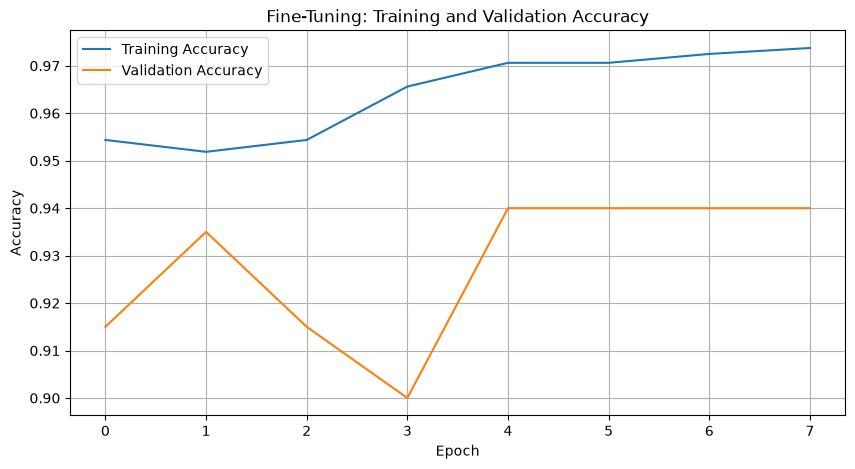

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuning: Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

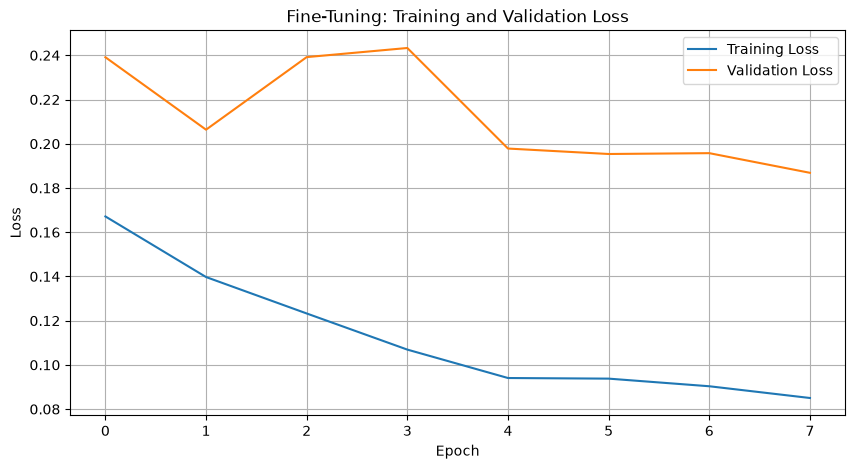

In [53]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning: Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

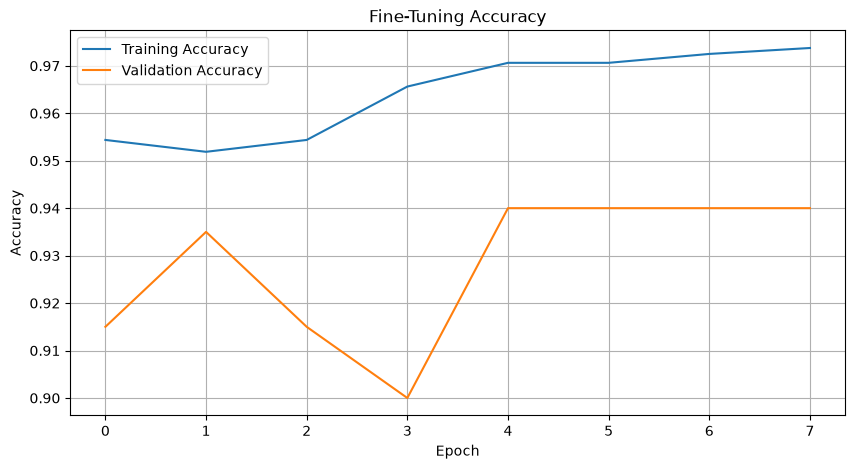

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuning Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        results_dir,
        "fine_tuning_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

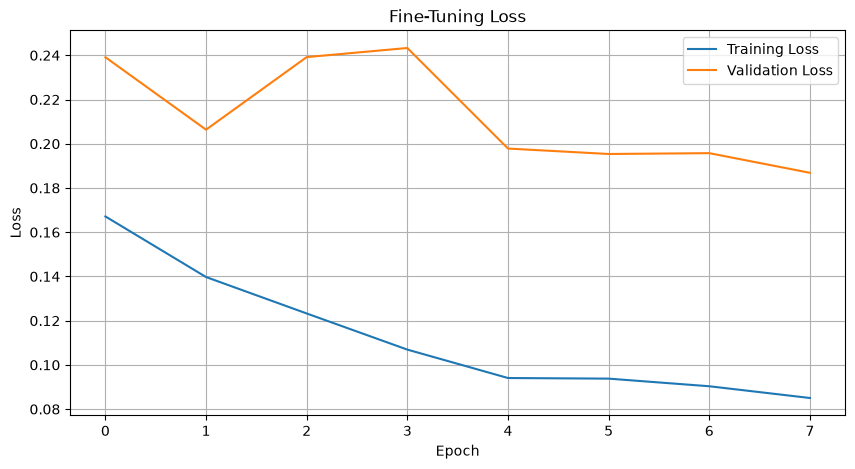

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        results_dir,
        "fine_tuning_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## FINAL MODEL EVALUATION


In [56]:
best_finetuned_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "mobilenetv2_finetuned_best.keras"
)

final_model = tf.keras.models.load_model(
    best_finetuned_path
)

print("Best fine-tuned model loaded successfully.")
print("Model path:")
print(best_finetuned_path)

Best fine-tuned model loaded successfully.
Model path:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\models\mobilenetv2_finetuned_best.keras


In [57]:
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)

Input shape: (None, 224, 224, 3)
Output shape: (None, 4)


## EVAL ON TEST DATASET

In [58]:
print("Evaluating final model on the test set...")

test_loss, test_accuracy = final_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nFinal Test Results")
print("-" * 40)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Evaluating final model on the test set...
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 562ms/step - accuracy: 0.9550 - loss: 0.1231

Final Test Results
----------------------------------------
Test Loss: 0.1231
Test Accuracy: 95.50%


In [59]:
final_test_accuracy = test_accuracy
final_test_loss = test_loss

print(f"Final test accuracy: {final_test_accuracy * 100:.2f}%")
print(f"Final test loss: {final_test_loss:.4f}")

Final test accuracy: 95.50%
Final test loss: 0.1231


## GENERATE PREDICTIONS

In [60]:
import numpy as np

y_true = []
y_pred = []
y_probabilities = []

for images, labels in test_dataset:
    
    predictions = final_model.predict(
        images,
        verbose=0
    )
    
    predicted_classes = np.argmax(
        predictions,
        axis=1
    )
    
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)
    y_probabilities.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probabilities = np.array(y_probabilities)

print("Number of test images:", len(y_true))
print("Number of predictions:", len(y_pred))

Number of test images: 200
Number of predictions: 200


In [61]:
for i in range(10):
    print(
        f"Actual: {class_names[y_true[i]]:15s} | "
        f"Predicted: {class_names[y_pred[i]]}"
    )

Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: healthy
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: early_blight
Actual: early_blight    | Predicted: late_blight


In [62]:
from sklearn.metrics import (
    classification_report,
    accuracy_score
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

Accuracy: 95.50%

Classification Report
              precision    recall  f1-score   support

early_blight     0.9778    0.8800    0.9263        50
     healthy     0.9804    1.0000    0.9901        50
 late_blight     0.9216    0.9400    0.9307        50
   leaf_mold     0.9434    1.0000    0.9709        50

    accuracy                         0.9550       200
   macro avg     0.9558    0.9550    0.9545       200
weighted avg     0.9558    0.9550    0.9545       200



## MARKDOWN


In [63]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

[[44  1  4  1]
 [ 0 50  0  0]
 [ 1  0 47  2]
 [ 0  0  0 50]]


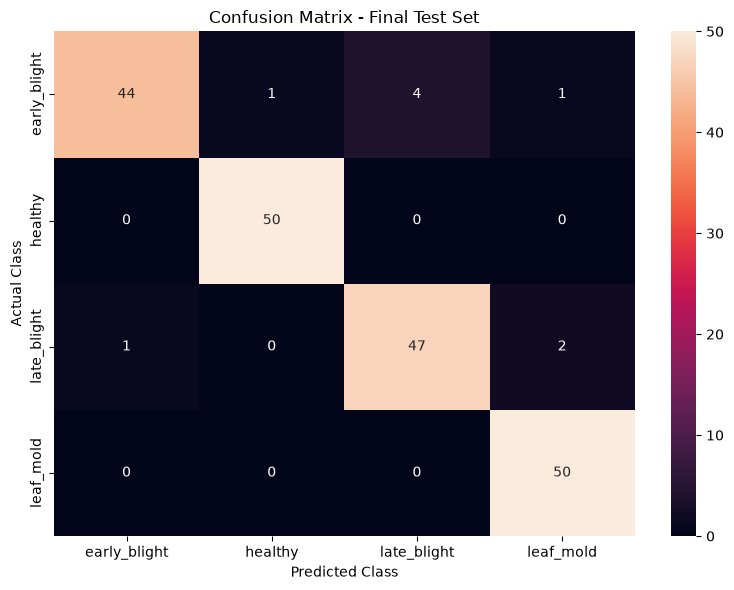

In [64]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Final Test Set")

plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## CALC CORRECT AND ICORRECT PREDICTIONS


In [65]:
correct_predictions = np.sum(
    y_true == y_pred
)

incorrect_predictions = np.sum(
    y_true != y_pred
)

total_predictions = len(y_true)

print("Total test images:", total_predictions)
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)

print(
    f"\nAccuracy: "
    f"{correct_predictions / total_predictions * 100:.2f}%"
)

Total test images: 200
Correct predictions: 191
Incorrect predictions: 9

Accuracy: 95.50%


### ACCURACY CHECK FOR EACH DISEASE


In [66]:
from sklearn.metrics import accuracy_score

print("Per-class accuracy")
print("=" * 40)

for i, class_name in enumerate(class_names):
    
    mask = y_true == i
    
    class_accuracy = np.mean(
        y_pred[mask] == i
    )
    
    print(
        f"{class_name:15s}: "
        f"{class_accuracy * 100:.2f}%"
    )

Per-class accuracy
early_blight   : 88.00%
healthy        : 100.00%
late_blight    : 94.00%
leaf_mold      : 100.00%


In [67]:
cm_no_diagonal = cm.copy()

np.fill_diagonal(
    cm_no_diagonal,
    0
)

max_confusion = np.unravel_index(
    np.argmax(cm_no_diagonal),
    cm_no_diagonal.shape
)

actual_class = class_names[max_confusion[0]]
predicted_class = class_names[max_confusion[1]]
confusion_count = cm_no_diagonal[max_confusion]

print("Most common confusion:")
print(
    f"Actual: {actual_class}"
)
print(
    f"Predicted: {predicted_class}"
)
print(
    f"Number of errors: {confusion_count}"
)

Most common confusion:
Actual: early_blight
Predicted: late_blight
Number of errors: 4


In [68]:
test_images = []
test_labels = []

for images, labels in test_dataset:
    test_images.extend(images.numpy())
    test_labels.extend(labels.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

print("Test image array shape:", test_images.shape)
print("Test label array shape:", test_labels.shape)

Test image array shape: (200, 224, 224, 3)
Test label array shape: (200,)


### DISPLAYING SOME MISTAKES

In [69]:
wrong_indices = np.where(
    y_true != y_pred
)[0]

print(
    "Number of misclassified images:",
    len(wrong_indices)
)

Number of misclassified images: 9


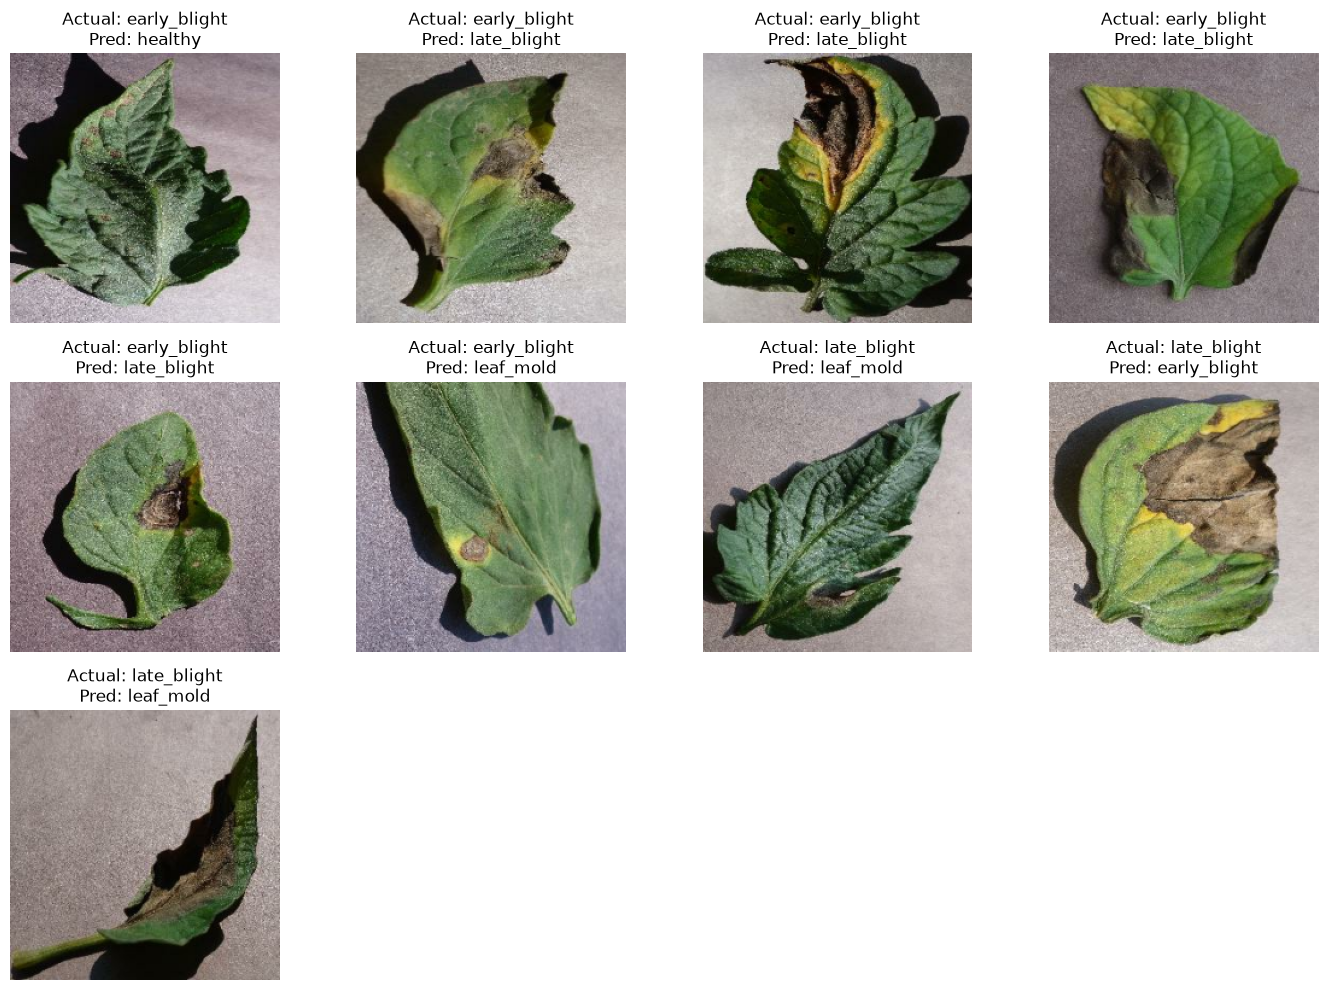

In [71]:
num_to_display = min(
    12,
    len(wrong_indices)
)

plt.figure(figsize=(14, 10))

for plot_index in range(num_to_display):
    
    idx = wrong_indices[plot_index]
    
    plt.subplot(3, 4, plot_index + 1)
    
    plt.imshow(
        test_images[idx].astype("uint8")
    )
    
    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    
    plt.axis("off")

plt.tight_layout()
plt.show()

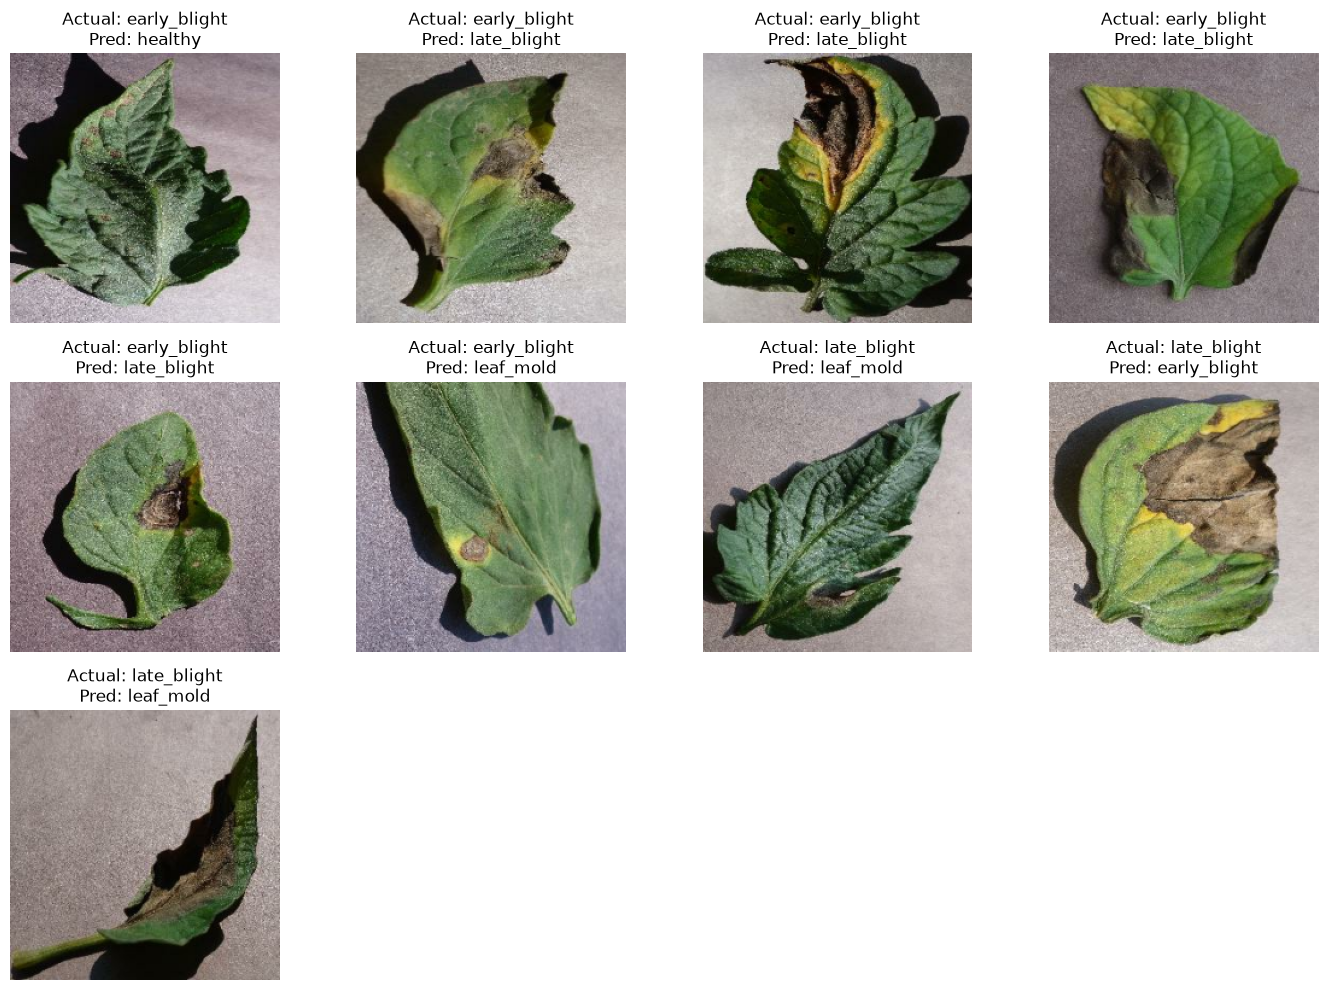

In [73]:
plt.figure(figsize=(14, 10))

for plot_index in range(num_to_display):
    
    idx = wrong_indices[plot_index]
    
    plt.subplot(3, 4, plot_index + 1)
    
    plt.imshow(
        test_images[idx].astype("uint8")
    )
    
    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "misclassified_examples.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## MODEL COMPARISON TABLE


In [74]:
comparison = pd.DataFrame({
    "Model": [
        "MobileNetV2 - Frozen",
        "MobileNetV2 - Fine-Tuned"
    ],
    "Validation Accuracy (%)": [
        best_val_accuracy * 100,
        best_fine_tune_accuracy * 100
    ]
})

comparison

,Model,Validation Accuracy (%)
0,MobileNetV2 - Frozen,91.000003
1,MobileNetV2 - Fine-Tuned,94.000000


In [75]:
comparison["Test Accuracy (%)"] = [
    np.nan,
    final_test_accuracy * 100
]

comparison

,Model,Validation Accuracy (%),Test Accuracy (%)
0,MobileNetV2 - Frozen,91.000003,NaN
1,MobileNetV2 - Fine-Tuned,94.000000,95.499998


## SAVING FINAL METRICS


In [76]:
import json

report_metrics = {
    "frozen_model_validation_accuracy": float(
        best_val_accuracy
    ),
    "fine_tuned_model_validation_accuracy": float(
        best_fine_tune_accuracy
    ),
    "final_test_accuracy": float(
        final_test_accuracy
    ),
    "final_test_loss": float(
        final_test_loss
    ),
    "total_test_images": int(
        total_predictions
    ),
    "correct_predictions": int(
        correct_predictions
    ),
    "incorrect_predictions": int(
        incorrect_predictions
    )
}

metrics_path = os.path.join(
    results_dir,
    "final_metrics.json"
)

with open(
    metrics_path,
    "w"
) as f:
    json.dump(
        report_metrics,
        f,
        indent=4
    )

print("Final metrics saved to:")
print(metrics_path)

Final metrics saved to:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\results\final_metrics.json


In [77]:
classification_report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

classification_report_path = os.path.join(
    results_dir,
    "classification_report.txt"
)

with open(
    classification_report_path,
    "w"
) as f:
    f.write(classification_report_text)

print("Classification report saved to:")
print(classification_report_path)

Classification report saved to:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\results\classification_report.txt
